# Developed Markets Equity Scorecard
**US · Eurozone · UK · Switzerland · Japan** — relative 3–6 month outlook

**Pipeline:** data cleaning → implied price & returns → 4 signals (macro / micro / valuation / technical) → predictive-power tests → pillar scores → composite ranking → backtest → current view.

**Design rules (locked before looking at results):**
* One signal per pillar, signs set *ex ante* from economic rationale (never flipped after seeing results).
* Equal pillar weights (25% each) — nothing is fitted, so there is no parameter search and no selection bias from optimisation.
* No look-ahead: every signal uses only data available at month-end *t*; trades are earned over *t → t+1*.
* Everything reported as it comes out, including weak results.

## 0. Setup & locked parameters

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
import statsmodels.api as sm
from IPython.display import display, Markdown

pd.options.display.float_format = '{:,.3f}'.format
pd.options.display.width = 200
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'font.size': 10})

ROOT = Path('..').resolve()
RAW, DATA, OUT = ROOT/'data'/'raw', ROOT/'data', ROOT/'output'
CH = OUT/'charts'
for p in (OUT, CH): p.mkdir(parents=True, exist_ok=True)

# ---- locked parameters -------------------------------------------------------
COUNTRIES   = ['US', 'Eurozone', 'UK', 'Switzerland', 'Japan']
PMI_LAG     = 1      # months: PMI for month t is published ~1st business day of t+1 -> use t-1 (no look-ahead)
PMI_CHG     = 3      # macro   : 3-month change in PMI
EPS_CHG     = 3      # micro   : 3-month % change in forward EPS (consensus revision proxy)
MIN_HIST    = 60     # valuation: expanding window, min 60 months of P/E history
MOM_LOOK, MOM_SKIP = 12, 1   # technical: 12-1 month price momentum
HORIZONS    = [3, 6] # predictive-power / holding horizons (months)
H_SET       = [1, 3, 6]  # backtest holding horizons (months); 3 = headline
N_PERM, SEED = 5000, 7
PILLARS     = {'macro': 'Macro: PMI 3M change',
               'micro': 'Micro: EPS 3M revision',
               'val':   'Valuation: fwd P/E z-score (inverted)',
               'tech':  'Technical: 12-1M momentum'}
PCOLS = {'macro': '#1f77b4', 'micro': '#ff7f0e', 'val': '#2ca02c', 'tech': '#9467bd'}

## 1. Data loading & cleaning
Which columns are used for each market (from the assignment mapping):

| Market | P/E | EPS | PMI | FX (→ USD) |
|---|---|---|---|---|
| US | BEst P/E Ratio | Monthly_EPS | NAPMPMI | – (USD) |
| Eurozone | BEst P/E Ratio | BEst EPS | MPMIEZMA | EURUSD |
| UK | BEst P/E Ratio | BEst EPS | MPMIGBMA | GBPUSD |
| Switzerland | BEst P/E Ratio | BEst EPS | CH_PMI | 1 / USDCHF |
| Japan | BEst P/E Ratio | BEst EPS | JPYPMI | 1 / USDJPY |

In [2]:
SPEC = {
 'US':          dict(file='US_raw_data.xlsx',  eps='Monthly_EPS', pmi='NAPMPMI Index',   fx=None),
 'Eurozone':    dict(file='EUR_raw_data.xlsx', eps='BEst EPS',    pmi='MPMIEZMA Index',  fx=('EURUSD BGN Curncy', 'direct')),
 'UK':          dict(file='UK_raw_data.xlsx',  eps='BEst EPS',    pmi='MPMIGBMA Index',  fx=('GBPUSD BGN Curncy', 'direct')),
 'Switzerland': dict(file='CH_raw_data.xlsx',  eps='BEst EPS',    pmi='CH_PMI',          fx=('USDCHF Curncy', 'invert')),
 'Japan':       dict(file='JPY_raw_data.xlsx', eps='BEst EPS',    pmi='JPYPMI',          fx=('USDJPY BGN Curncy', 'invert')),
}
PE_COL = 'BEst P/E Ratio'

def load_country(name, s):
    d = pd.read_excel(RAW/s['file'])
    n_raw = len(d)
    d = d.dropna(subset=['Date']).copy()                       # UK / CH files contain blank-date filler rows
    d['month'] = pd.to_datetime(d['Date']).dt.to_period('M')   # align everything on calendar month
    d = d.sort_values('Date').drop_duplicates('month', keep='last').set_index('month')   # EUR/JPY are newest-first
    out = pd.DataFrame({'pe': d[PE_COL], 'eps': d[s['eps']], 'pmi': d[s['pmi']]})
    if s['fx'] is None:
        out['fx'] = 1.0
    else:
        col, how = s['fx']
        out['fx'] = d[col] if how == 'direct' else 1.0 / d[col]   # fx = USD per 1 unit of local currency
    return out, n_raw

frames, qa = {}, []
for c in COUNTRIES:
    frames[c], n_raw = load_country(c, SPEC[c])
    f = frames[c]
    qa.append(dict(Market=c, raw_rows=n_raw, clean_months=len(f), first=str(f.pe.first_valid_index()),
                   last=str(f.index.max()), missing_PE=int(f.pe.isna().sum()), missing_EPS=int(f.eps.isna().sum()),
                   missing_PMI=int(f.pmi.isna().sum())))
display(pd.DataFrame(qa).set_index('Market'))

PE  = pd.DataFrame({c: frames[c].pe  for c in COUNTRIES})
EPS = pd.DataFrame({c: frames[c].eps for c in COUNTRIES})
PMI = pd.DataFrame({c: frames[c].pmi for c in COUNTRIES})
FX  = pd.DataFrame({c: frames[c].fx  for c in COUNTRIES})

# common window = first month with P/E & EPS for all five  ->  last month available for all five (US file ends Apr-2026)
START = max(PE[c].first_valid_index() for c in COUNTRIES)
AS_OF = min(frames[c].index.max() for c in COUNTRIES)
print(f'Common window: {START} -> {AS_OF}  ({len(pd.period_range(START, AS_OF, freq="M"))} months)')
for df in (PE, EPS, PMI, FX):
    df.drop(df.index[df.index > AS_OF], inplace=True)       # truncate to common end (UK/CH have partial Jul-2026 rows)
win = pd.period_range(START, AS_OF, freq='M')
assert PE.loc[win].notna().all().all() and EPS.loc[win].notna().all().all() and PMI.loc[win].notna().all().all() and FX.loc[win].notna().all().all()
print('No missing values inside the common window for P/E, EPS, PMI, FX.')

,raw_rows,clean_months,first,last,missing_PE,missing_EPS,missing_PMI
Market,,,,,,,
US,256,256,2005-01,2026-04,0,0,0
Eurozone,360,360,2005-12,2026-06,113,113,11
UK,376,361,2005-12,2026-07,113,113,0
Switzerland,361,248,2005-12,2026-07,0,0,0
Japan,253,253,2005-06,2026-06,0,0,0


Common window: 2005-12 -> 2026-04  (245 months)
No missing values inside the common window for P/E, EPS, PMI, FX.


**Data note — `Price_data_all_countries.xlsx` does not contain prices.** Its values match the P/E columns of the raw files to within
~0.2 turns (cross-check below; value ranges 8–39 are P/E multiples, not index levels), so it cannot be used for returns. **Decision (yours): use implied price = forward P/E × forward EPS.**

In [3]:
px_file = pd.read_excel(RAW/'Price_data_all_countries.xlsx')
chk = []
for lab, (dcol, vcol) in {'US': ('US', 'SPX Index'), 'Eurozone': ('Eurozone ', 'MXEM Index'), 'UK': ('UK', 'MXGB Index'),
                          'Switzerland': ('Switzerland', 'MXCH Index'), 'Japan': ('Japan', 'MXJP Index')}.items():
    s = px_file[[dcol, vcol]].dropna(); s.index = pd.to_datetime(s[dcol]).dt.to_period('M'); s = s[vcol]
    j = pd.concat([s.rename('file'), PE[lab].rename('raw_pe')], axis=1).dropna()
    chk.append(dict(Market=lab, overlap_months=len(j), max_abs_diff_vs_raw_PE=(j.file - j.raw_pe).abs().max(),
                    file_value_range=f'{s.min():.1f} – {s.max():.1f}'))
display(pd.DataFrame(chk).set_index('Market'))

,overlap_months,max_abs_diff_vs_raw_PE,file_value_range
Market,,,
US,256,0.055,10.5 – 24.8
Eurozone,245,0.019,8.0 – 18.3
UK,245,0.005,7.7 – 16.1
Switzerland,245,0.010,10.4 – 20.4
Japan,251,0.190,11.1 – 39.2


## 2. Implied price & returns
* `Implied price (local) = Forward P/E × Forward EPS` · `USD price = local price × (USD per local FX)`
* Returns are **price-index** returns (no dividends) — a proxy for the MSCI/SPX index returns, reported in **local currency and USD**.
* Sanity check: the worst months should be the known crises.

In [4]:
PX     = PE * EPS                       # implied local price index
PX_USD = PX * FX                        # implied USD price index
R_LOC  = PX.pct_change()                # 1M return ending at t (local)
R_USD  = PX_USD.pct_change()            # 1M return ending at t (USD)
fwd = {('local', h): PX.shift(-h) / PX - 1 for h in HORIZONS}          # forward h-month return from t
fwd.update({('USD', h): PX_USD.shift(-h) / PX_USD - 1 for h in HORIZONS})

worst = {c: [f'{str(m)} ({v:.1%})' for m, v in R_LOC.loc[win, c].nsmallest(3).items()] for c in COUNTRIES}
display(pd.DataFrame(worst, index=['worst 1', 'worst 2', 'worst 3']).T)

,worst 1,worst 2,worst 3
US,2008-10 (-17.0%),2020-03 (-12.5%),2009-02 (-11.0%)
Eurozone,2020-03 (-17.3%),2008-10 (-15.8%),2011-08 (-13.0%)
UK,2020-03 (-13.8%),2008-09 (-13.0%),2008-10 (-10.8%)
Switzerland,2009-02 (-11.0%),2008-01 (-9.6%),2026-03 (-8.6%)
Japan,2008-10 (-21.1%),2008-09 (-13.8%),2026-03 (-11.4%)


## 3. Signal construction (one per pillar, direction fixed ex ante)

| Pillar | Signal | Economic rationale | Direction |
|---|---|---|---|
| **Macro** | 3-month change in manufacturing PMI (lagged 1M for publication) | Improving activity momentum precedes earnings upgrades and equity outperformance | higher = better |
| **Micro** | 3-month % change in forward EPS | Analyst upgrades/downgrades drive absolute and relative returns (earnings-revision effect) | higher = better |
| **Valuation** | Forward P/E z-score vs own expanding history (≥60M) | Cheap vs own history ⇒ higher subsequent returns (mean reversion in multiples) | lower P/E = better (sign inverted) |
| **Technical** | 12-1 month price momentum (skip latest month) | Cross-sectional trend persistence; skipping 1M avoids short-term reversal | higher = better |

Each raw signal is turned into a **cross-sectional z-score across the five markets every month** → comparable pillar scores (mean 0, std 1).

Scorecard window (all 4 pillars valid for all 5 markets): 2010-11 -> 2026-04  (186 months)
Binding constraint = valuation (needs 60M of P/E history).


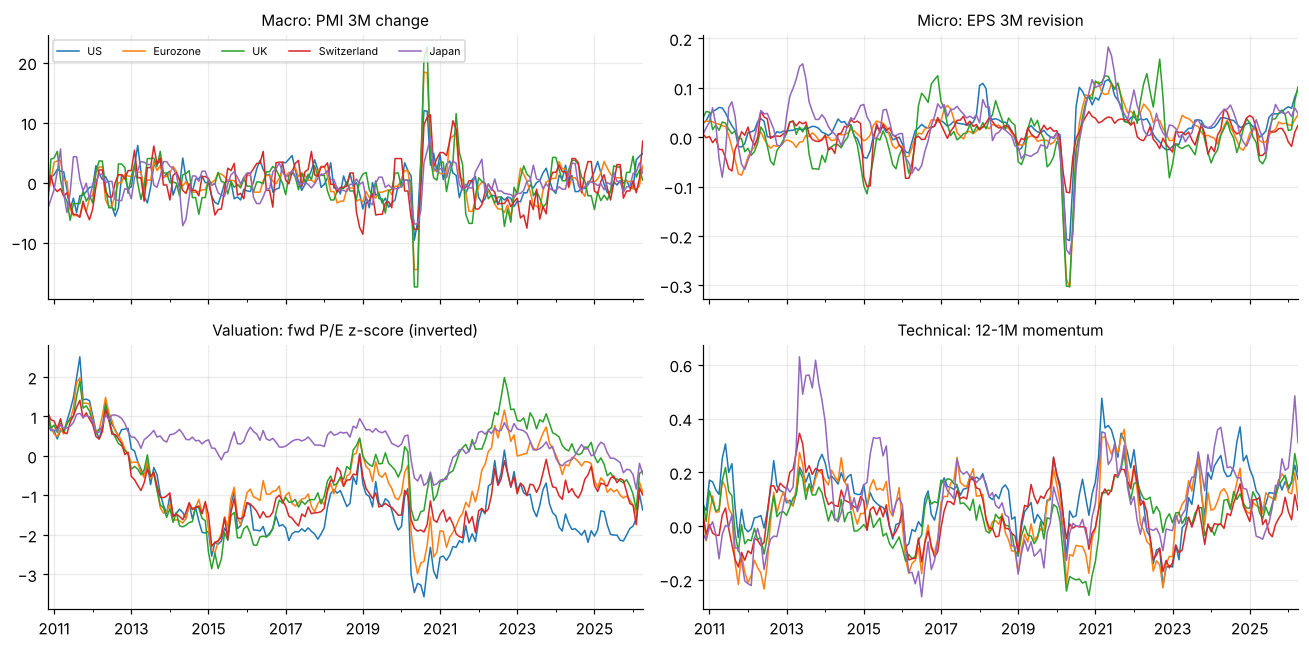

In [5]:
def cs_z(df):
    """cross-sectional z-score across countries each month (NaN row if any country missing)"""
    ok = df.notna().all(axis=1)
    z = df.sub(df.mean(axis=1), axis=0).div(df.std(axis=1, ddof=1), axis=0)
    return z.where(ok)

def build_raw_signals(PE, EPS, PMI, PX):
    return {
     'macro': PMI.shift(PMI_LAG) - PMI.shift(PMI_LAG + PMI_CHG),
     'micro': EPS / EPS.shift(EPS_CHG) - 1,
     'val':   -(PE - PE.expanding(MIN_HIST).mean()) / PE.expanding(MIN_HIST).std(),
     'tech':  PX.shift(MOM_SKIP) / PX.shift(MOM_LOOK) - 1,
    }
RAW_SIG = build_raw_signals(PE, EPS, PMI, PX)
Z = {k: cs_z(v.loc[win]) for k, v in RAW_SIG.items()}
SIG_START = max(z.dropna().index.min() for z in Z.values())
Z = {k: z.loc[SIG_START:] for k, z in Z.items()}
SIG_IDX = Z['macro'].index
print(f'Scorecard window (all 4 pillars valid for all 5 markets): {SIG_IDX[0]} -> {SIG_IDX[-1]}  ({len(SIG_IDX)} months)')
print('Binding constraint = valuation (needs 60M of P/E history).')

fig, ax = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
for a, (k, lab) in zip(ax.ravel(), PILLARS.items()):
    RAW_SIG[k].loc[SIG_IDX].plot(ax=a, lw=1)
    a.set_title(lab, fontsize=10); a.legend(fontsize=7, ncol=5, loc='upper left') if k == 'macro' else a.get_legend() and a.get_legend().remove()
plt.tight_layout(); plt.show()

## 4. Predictive-power assessment
For each signal and each horizon *h* (3M, 6M), in local and USD terms, every month:
* **Rank IC** = Spearman correlation across the 5 markets between the signal at *t* and the forward *h*-month return.
* **Spread** = average forward return of the top-2 markets minus the bottom-2 markets.

**Inference:** forward returns overlap, so t-stats use Newey-West (lags = h). Because signal directions were fixed ex ante, the permutation
p-value is **one-sided (IC > 0)**: country labels of the signal are shuffled **in blocks of h months** (keeps the overlap/persistence
structure), 5,000 draws. With only 5 markets and ~185 months, power is limited — read t-stats accordingly.

In [6]:
def rank_ic(sig, f):
    idx = sig.index.intersection(f.dropna().index)
    s, r = sig.loc[idx].rank(axis=1), f.loc[idx].rank(axis=1)
    s, r = s.sub(s.mean(axis=1), axis=0), r.sub(r.mean(axis=1), axis=0)
    return (s * r).sum(axis=1) / np.sqrt((s**2).sum(axis=1) * (r**2).sum(axis=1))

def top_bottom_spread(sig, f):
    idx = sig.index.intersection(f.dropna().index)
    rk = sig.loc[idx].rank(axis=1)
    return (f.loc[idx].where(rk >= 4).mean(axis=1)) - (f.loc[idx].where(rk <= 2).mean(axis=1))

def nw_t(x, lags):
    x = x.dropna()
    m = sm.OLS(x.values, np.ones(len(x))).fit(cov_type='HAC', cov_kwds={'maxlags': lags})
    return float(m.tvalues[0])

def block_perm_p(sig, f, h, n_perm=N_PERM, seed=SEED):
    idx = sig.index.intersection(f.dropna().index)
    S = sig.loc[idx].rank(axis=1).to_numpy(copy=True); F = f.loc[idx].rank(axis=1).to_numpy(copy=True)
    S = S - S.mean(1, keepdims=True); F = F - F.mean(1, keepdims=True)
    denom = np.sqrt((S**2).sum(1) * (F**2).sum(1))
    obs = ((S * F).sum(1) / denom).mean()
    T = len(idx); blk = np.arange(T) // h; B = blk.max() + 1
    rng = np.random.default_rng(seed)
    perms = np.argsort(rng.random((n_perm, B, S.shape[1])), axis=2)[:, blk, :]       # (P,T,N)
    Sp = np.take_along_axis(np.broadcast_to(S, (n_perm,) + S.shape), perms, axis=2)
    null = ((Sp * F).sum(2) / denom).mean(1)
    return (np.sum(null >= obs) + 1) / (n_perm + 1)

# composite (equal-weight pillars) is defined here so it can be tested alongside the single signals
COMP = sum(Z.values()) / len(Z)           # mean of 4 pillar z-scores (mean 0 across markets by construction)

TEST = {**{PILLARS[k]: Z[k] for k in PILLARS}, 'COMPOSITE (equal-weight)': COMP}
rows = []
for name, sig in TEST.items():
    for basis in ('local', 'USD'):
        for h in HORIZONS:
            f = fwd[(basis, h)]
            ic = rank_ic(sig, f); sp = top_bottom_spread(sig, f)
            half = len(ic) // 2
            rows.append({'Signal': name, 'Basis': basis, 'Horizon (M)': h, 'N months': len(ic),
                         'Mean IC': ic.mean(), 'IC t-stat (NW)': nw_t(ic, h), 'IC hit-rate': (ic > 0).mean(),
                         'IC 1st half': ic.iloc[:half].mean(), 'IC 2nd half': ic.iloc[half:].mean(),
                         'Top2-Bottom2 spread %': sp.mean() * 100, 'Spread t-stat (NW)': nw_t(sp, h),
                         'Perm p-value (1-sided)': block_perm_p(sig, f, h)})
PP = pd.DataFrame(rows)
display(PP.set_index(['Signal', 'Basis', 'Horizon (M)']).style.format({
    'Mean IC': '{:.3f}', 'IC t-stat (NW)': '{:.2f}', 'IC hit-rate': '{:.0%}', 'IC 1st half': '{:.3f}', 'IC 2nd half': '{:.3f}',
    'Top2-Bottom2 spread %': '{:.2f}', 'Spread t-stat (NW)': '{:.2f}', 'Perm p-value (1-sided)': '{:.3f}'}))

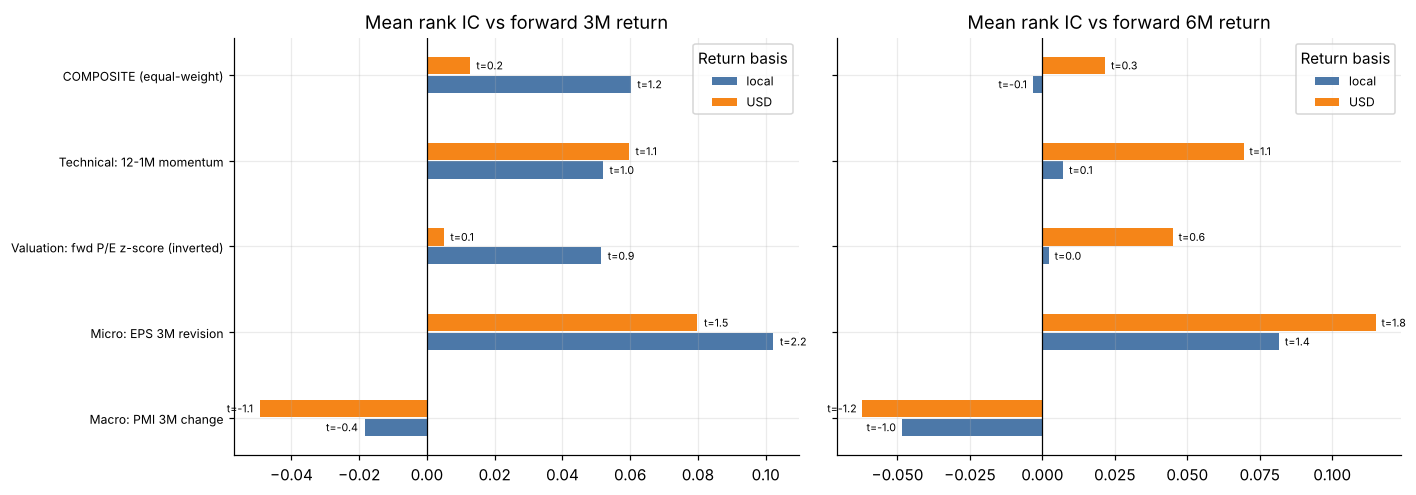

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
names = list(TEST.keys()); y = np.arange(len(names)); w = 0.2
for ax, h in zip(axes, HORIZONS):
    for i, basis in enumerate(('local', 'USD')):
        d = PP[(PP['Horizon (M)'] == h) & (PP.Basis == basis)].set_index('Signal').loc[names]
        ax.barh(y + (i - .5) * w * 1.1, d['Mean IC'], height=w, label=basis,
                color=['#4c78a8', '#f58518'][i])
        for yy, ic_, t_ in zip(y + (i - .5) * w * 1.1, d['Mean IC'], d['IC t-stat (NW)']):
            ax.text(ic_ + (0.002 if ic_ >= 0 else -0.002), yy, f't={t_:.1f}', va='center', ha='left' if ic_ >= 0 else 'right', fontsize=7)
    ax.axvline(0, color='k', lw=.8); ax.set_title(f'Mean rank IC vs forward {h}M return'); ax.set_yticks(y); ax.set_yticklabels(names, fontsize=8)
    ax.invert_yaxis(); ax.legend(title='Return basis', fontsize=8)
plt.tight_layout(); plt.savefig(CH/'fig_predictive_power.png', dpi=200, bbox_inches='tight'); plt.show()

## 5. Scorecard construction
1. **Pillar scores** = cross-sectional z-score of each signal (Macro, Micro, Valuation, Technical).
2. **Aggregate country score** = equal-weight average of the 4 pillar scores (25% each — deliberately *not* optimised).
3. **Ranking** = 1 (best) … 5 (worst). **Stance**: ranks 1–2 = Overweight, rank 3 = Neutral, ranks 4–5 = Underweight.

In [8]:
STANCE = {1: 'Overweight', 2: 'Overweight', 3: 'Neutral', 4: 'Underweight', 5: 'Underweight'}
RANK = COMP.rank(axis=1, ascending=False)

print('Cross-sectional correlation between pillar scores (are the pillars adding different information?)')
display(pd.DataFrame({PILLARS[k]: pd.concat([Z[k][c] for c in COUNTRIES]).reset_index(drop=True) for k in PILLARS}).corr())

cur = pd.DataFrame({PILLARS[k]: Z[k].loc[AS_OF] for k in PILLARS})
cur.columns = ['Macro', 'Micro', 'Valuation', 'Technical']
cur['Composite score'] = COMP.loc[AS_OF]
cur['Rank'] = RANK.loc[AS_OF].astype(int)
cur['Stance'] = cur['Rank'].map(STANCE)
cur = cur.sort_values('Rank')
display(cur)

Cross-sectional correlation between pillar scores (are the pillars adding different information?)


,Macro: PMI 3M change,Micro: EPS 3M revision,Valuation: fwd P/E z-score (inverted),Technical: 12-1M momentum
Macro: PMI 3M change,1.000,-0.010,-0.010,0.088
Micro: EPS 3M revision,-0.010,1.000,0.048,0.469
Valuation: fwd P/E z-score (inverted),-0.010,0.048,1.000,-0.065
Technical: 12-1M momentum,0.088,0.469,-0.065,1.000


,Macro,Micro,Valuation,Technical,Composite score,Rank,Stance
UK,-1.121,1.127,1.089,0.336,0.358,1,Overweight
Japan,-0.657,-0.441,0.887,1.452,0.310,2,Overweight
US,0.580,0.978,-1.347,0.049,0.065,3,Neutral
Switzerland,1.392,-1.144,-0.406,-1.130,-0.322,4,Underweight
Eurozone,-0.193,-0.520,-0.223,-0.707,-0.411,5,Underweight


## 6. Backtest
**Construction (all assumptions explicit):**
* Score at month-end *t* → positions earned over *t → t+1*; trades at month-end close; **no transaction costs / slippage** (gross) — break-even cost is reported instead.
* **Strategy A — score-weighted long/short (headline):** weight ∝ composite score, scaled so longs = +100%, shorts = −100% (dollar-neutral).
* **Strategy B — long-only top-2 vs equal-weight 5-market benchmark:** 50% / 50% in the two highest-ranked markets; benchmark = 20% each.
* **Holding horizon H** (months): weights = average of the last H monthly signals (overlapping tranches, standard for a 3-6M view). H=1 is plain monthly rebalancing; **H=3 is the headline**, H=6 shown as well.
* Both local-currency and USD returns. Sharpe uses rf = 0 (L/S is self-financing; for B the information ratio is vs. the benchmark).

In [9]:
def base_w_ls(score):
    return score.div(score.clip(lower=0).sum(axis=1), axis=0)          # longs sum +1, shorts sum -1

def base_w_lo(score):
    rk = score.rank(axis=1, ascending=False)
    return (rk <= 2).astype(float) / 2

def held(wbase, H):
    return wbase.rolling(H, min_periods=1).mean()                       # tranche average (ramp-up uses available tranches)

def port_ret(w, r):
    ww = w.shift(1).dropna(how='any')                                   # weights set at t earn return of month t+1
    rr = r.reindex(ww.index)
    return (ww * rr).sum(axis=1, min_count=1)

def max_dd(r):
    cum = (1 + r).cumprod(); return (cum / cum.cummax() - 1).min()

def stats(r, turnover=None, active=False):
    n = len(r); ann = (1 + r).prod() ** (12 / n) - 1; vol = r.std() * np.sqrt(12)
    d = {'Ann. return': ann, 'Ann. vol': vol, ('Info ratio' if active else 'Sharpe'): r.mean() * 12 / vol,
         'Max drawdown': max_dd(r), 'Hit rate (months)': (r > 0).mean(), 'Worst month': r.min()}
    if turnover is not None:
        d['Annual turnover (x)'] = turnover * 12
        d['Break-even cost (bps)'] = ann / (turnover * 12) * 1e4 if turnover > 0 else np.nan
    return d

BT, ROWS = {}, []
EW = pd.DataFrame(0.2, index=SIG_IDX, columns=COUNTRIES)
for basis, R in (('local', R_LOC), ('USD', R_USD)):
    for H in H_SET:
        w_ls = held(base_w_ls(COMP), H); w_lo = held(base_w_lo(COMP), H)
        r_ls = port_ret(w_ls, R); r_lo = port_ret(w_lo, R); r_bm = port_ret(EW, R)
        r_act = r_lo - r_bm
        BT[(basis, H)] = pd.DataFrame({'LS': r_ls, 'LongOnly_top2': r_lo, 'EW_benchmark': r_bm, 'Active': r_act})
        to_ls = w_ls.diff().abs().sum(axis=1).iloc[1:].mean(); to_lo = w_lo.diff().abs().sum(axis=1).iloc[1:].mean()
        ROWS.append({'Strategy': 'A. Score-weighted L/S', 'Basis': basis, 'H (M)': H, **stats(r_ls, to_ls)})
        ROWS.append({'Strategy': 'B. Long-only top-2 (absolute)', 'Basis': basis, 'H (M)': H, **stats(r_lo, to_lo)})
        ROWS.append({'Strategy': 'B. Top-2 minus EW benchmark (active)', 'Basis': basis, 'H (M)': H, **stats(r_act, to_lo, active=True)})
        ROWS.append({'Strategy': 'Benchmark: EW 5 markets', 'Basis': basis, 'H (M)': H, **stats(r_bm)})
STATS = pd.DataFrame(ROWS)
fmt = {'Ann. return': '{:.1%}', 'Ann. vol': '{:.1%}', 'Sharpe': '{:.2f}', 'Info ratio': '{:.2f}', 'Max drawdown': '{:.1%}',
       'Hit rate (months)': '{:.0%}', 'Worst month': '{:.1%}', 'Annual turnover (x)': '{:.1f}', 'Break-even cost (bps)': '{:.0f}'}
bt_start, bt_end = BT[('USD', 3)].dropna().index[[0, -1]]
print(f'Backtest window: {bt_start} -> {bt_end}  ({len(BT[("USD", 3)].dropna())} months)')
display(STATS.set_index(['Strategy', 'Basis', 'H (M)']).style.format(fmt, na_rep='–'))

Backtest window: 2010-12 -> 2026-04  (185 months)


,,,Ann. return,Ann. vol,Sharpe,Max drawdown,Hit rate (months),Worst month,Annual turnover (x),Break-even cost (bps),Info ratio
Strategy,Basis,H (M),,,,,,,,,
A. Score-weighted L/S,local,1,0.4%,9.3%,0.09,-20.8%,53%,-9.0%,14.8,3,–
B. Long-only top-2 (absolute),local,1,7.1%,12.8%,0.60,-22.9%,64%,-14.9%,6.2,115,–
B. Top-2 minus EW benchmark (active),local,1,-0.4%,4.6%,–,-22.0%,49%,-3.7%,6.2,-7,-0.07
Benchmark: EW 5 markets,local,1,7.6%,11.9%,0.67,-20.2%,66%,-11.4%,–,–,–
A. Score-weighted L/S,local,3,1.5%,8.6%,0.21,-19.5%,54%,-7.4%,7.9,19,–
B. Long-only top-2 (absolute),local,3,7.6%,12.4%,0.65,-20.9%,65%,-9.5%,3.6,212,–
B. Top-2 minus EW benchmark (active),local,3,-0.0%,3.8%,–,-11.6%,49%,-3.3%,3.6,-1,0.01
Benchmark: EW 5 markets,local,3,7.6%,11.9%,0.67,-20.2%,66%,-11.4%,–,–,–
A. Score-weighted L/S,local,6,0.6%,8.1%,0.12,-26.8%,54%,-7.9%,4.3,14,–


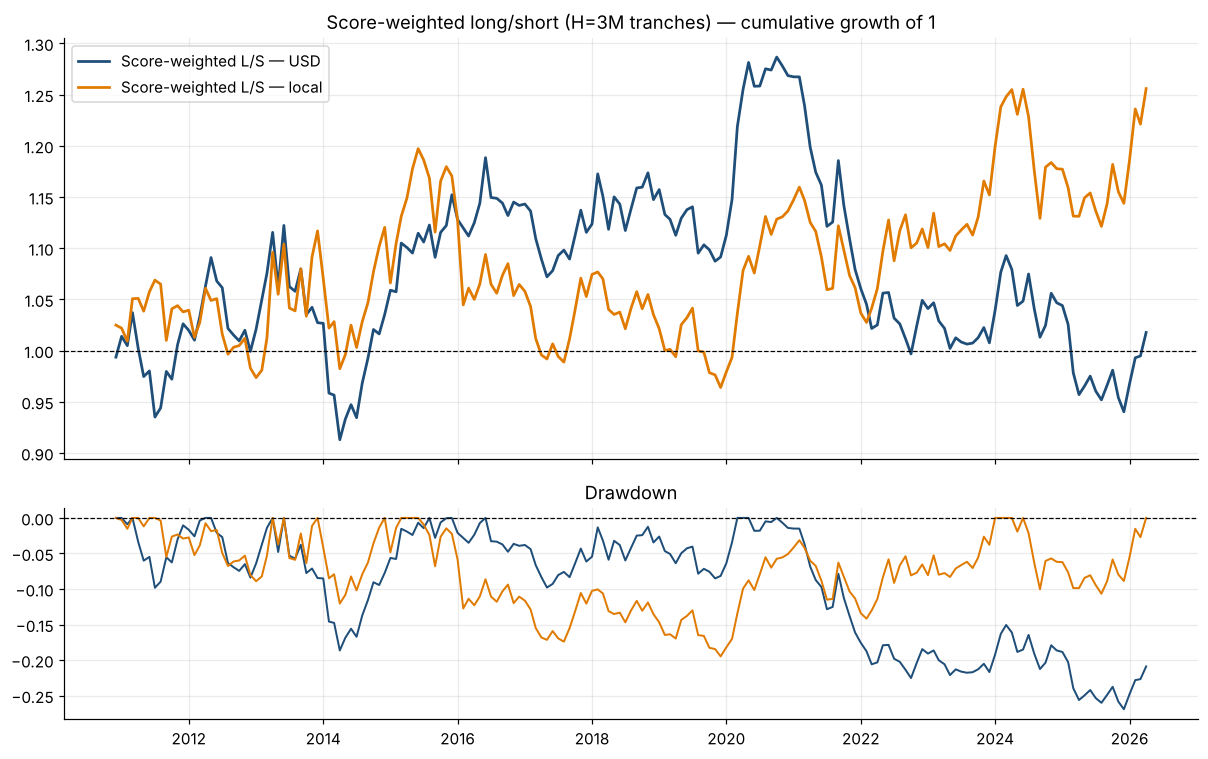

In [10]:
H0 = 3
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
for basis, col in (('USD', '#1f4e79'), ('local', '#e07b00')):
    r = BT[(basis, H0)]['LS'].dropna(); cum = (1 + r).cumprod()
    ax[0].plot(cum.index.to_timestamp(), cum, color=col, label=f'Score-weighted L/S — {basis}', lw=1.8)
    ax[1].plot(cum.index.to_timestamp(), cum / cum.cummax() - 1, color=col, lw=1.3)
ax[0].axhline(1, color='k', ls='--', lw=.8); ax[0].set_title(f'Score-weighted long/short (H={H0}M tranches) — cumulative growth of 1'); ax[0].legend()
ax[1].set_title('Drawdown'); ax[1].axhline(0, color='k', ls='--', lw=.8)
plt.tight_layout(); plt.savefig(CH/'fig_bt_longshort.png', dpi=200, bbox_inches='tight'); plt.show()

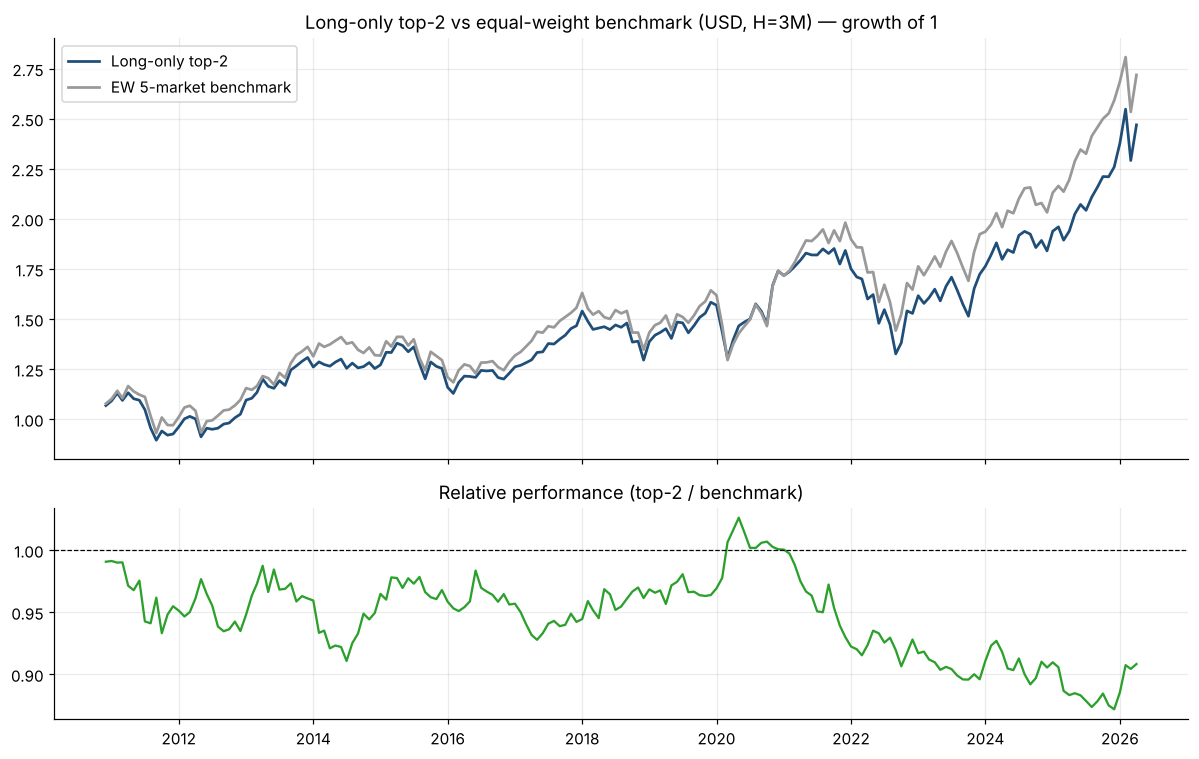

In [11]:
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
d = BT[('USD', H0)].dropna()
for col, lab, c in (('LongOnly_top2', 'Long-only top-2', '#1f4e79'), ('EW_benchmark', 'EW 5-market benchmark', '#999999')):
    cum = (1 + d[col]).cumprod(); ax[0].plot(cum.index.to_timestamp(), cum, label=lab, color=c, lw=1.8)
ax[0].set_title(f'Long-only top-2 vs equal-weight benchmark (USD, H={H0}M) — growth of 1'); ax[0].legend()
rel = (1 + d['LongOnly_top2']).cumprod() / (1 + d['EW_benchmark']).cumprod()
ax[1].plot(rel.index.to_timestamp(), rel, color='#2ca02c', lw=1.5); ax[1].axhline(1, color='k', ls='--', lw=.8); ax[1].set_title('Relative performance (top-2 / benchmark)')
plt.tight_layout(); plt.savefig(CH/'fig_bt_longonly.png', dpi=200, bbox_inches='tight'); plt.show()

### Diagnosis: which pillar carries the result?
*Diagnostic only* — pillar weights are **not** changed on the basis of this table (that would be fitting to the same history).

In [12]:
diag = []
for k in PILLARS:
    for basis, R in (('local', R_LOC), ('USD', R_USD)):
        r = port_ret(held(base_w_ls(Z[k]), 3), R).dropna()
        st_ = stats(r); diag.append({'Single-pillar L/S (H=3M)': PILLARS[k], 'Basis': basis, 'Ann. return': st_['Ann. return'],
                                     'Sharpe': st_['Sharpe'], 'Max drawdown': st_['Max drawdown']})
DIAG = pd.DataFrame(diag)
display(DIAG.set_index(['Single-pillar L/S (H=3M)', 'Basis']).style.format({'Ann. return': '{:.1%}', 'Sharpe': '{:.2f}', 'Max drawdown': '{:.1%}'}))

### Integrity checks (independent re-computation + look-ahead test)

In [13]:
from scipy.stats import spearmanr
# (1) IC for a random month recomputed with scipy
t = pd.Period('2018-05', 'M')
assert abs(spearmanr(COMP.loc[t], fwd[('USD', 3)].loc[t]).statistic - rank_ic(COMP, fwd[('USD', 3)]).loc[t]) < 1e-12
# (2) H=1 long/short return recomputed by hand for several months
rr = port_ret(held(base_w_ls(COMP), 1), R_LOC)
for t in [pd.Period(x, 'M') for x in ('2012-03', '2016-09', '2020-04', '2025-11')]:
    w = COMP.loc[t - 1] / COMP.loc[t - 1].clip(lower=0).sum()
    assert abs((w * R_LOC.loc[t]).sum() - rr.loc[t]) < 1e-12 and abs(w.sum()) < 1e-12 and abs(w.abs().sum() - 2) < 1e-12
# (3) look-ahead test: rebuild every signal using only data up to T; scores at T must be identical to the full-sample run
for T in [pd.Period('2014-06', 'M'), pd.Period('2021-09', 'M')]:
    rs = build_raw_signals(PE.loc[:T], EPS.loc[:T], PMI.loc[:T], PX.loc[:T])
    zt = sum(cs_z(v.loc[win[win <= T]]) for v in rs.values()) / 4
    assert np.allclose(zt.loc[T].values, COMP.loc[T].values), T
print('All integrity checks passed: IC matches scipy, L/S returns match manual calc (dollar-neutral, gross 200%), signals are free of look-ahead.')

All integrity checks passed: IC matches scipy, L/S returns match manual calc (dollar-neutral, gross 200%), signals are free of look-ahead.


### Do the results survive an adversarial check?
1. **Concentration by period** — is the P&L from a few years? 2. **Sub-periods** — is it consistent? 3. **Single-market dependence** — drop each market in turn.

In [14]:
r = BT[('USD', H0)]['LS'].dropna()
yr = r.groupby(r.index.year).apply(lambda x: (1 + x).prod() - 1)
print('Calendar-year return, USD L/S, H=3:'); display(yr.to_frame('Return').T.style.format('{:.1%}'))
print(f'Sum of all monthly returns = {r.sum():.1%};  best 5 months add {r.nlargest(5).sum():.1%};  worst 5 months subtract {r.nsmallest(5).sum():.1%}')
half = len(r) // 2
print('Sharpe  1st half: {:.2f}   2nd half: {:.2f}'.format(r.iloc[:half].mean()*12/(r.iloc[:half].std()*np.sqrt(12)),
                                                         r.iloc[half:].mean()*12/(r.iloc[half:].std()*np.sqrt(12))))

# leave-one-market-out: rebuild composite from 4 markets (z-scores recomputed across remaining 4) and re-run the H=3 USD L/S
lo_rows = []
for drop in COUNTRIES:
    keep = [c for c in COUNTRIES if c != drop]
    comp4 = sum(cs_z(RAW_SIG[k].loc[SIG_IDX, keep]) for k in PILLARS) / 4
    rr = port_ret(held(base_w_ls(comp4), H0), R_USD[keep]).dropna()
    lo_rows.append({'Dropped market': drop, 'Ann. return': (1 + rr).prod() ** (12 / len(rr)) - 1,
                    'Sharpe': rr.mean() * 12 / (rr.std() * np.sqrt(12)), 'Max drawdown': max_dd(rr)})
display(pd.DataFrame(lo_rows).set_index('Dropped market').style.format({'Ann. return': '{:.1%}', 'Sharpe': '{:.2f}', 'Max drawdown': '{:.1%}'}))

Calendar-year return, USD L/S, H=3:


,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Return,-0.6%,3.3%,-2.6%,2.8%,0.8%,11.3%,-0.9%,-2.3%,2.9%,-4.9%,16.2%,-14.9%,-2.8%,-4.0%,3.9%,-10.2%,8.2%


Sum of all monthly returns = 6.5%;  best 5 months add 26.1%;  worst 5 months subtract -26.0%
Sharpe  1st half: 0.21   2nd half: -0.13


,Ann. return,Sharpe,Max drawdown
Dropped market,,,
US,-1.9%,-0.19,-34.2%
Eurozone,1.4%,0.21,-22.8%
UK,-0.8%,-0.05,-28.4%
Switzerland,-0.9%,-0.06,-38.7%
Japan,2.9%,0.44,-15.9%


## 7. Current ranking & investment view

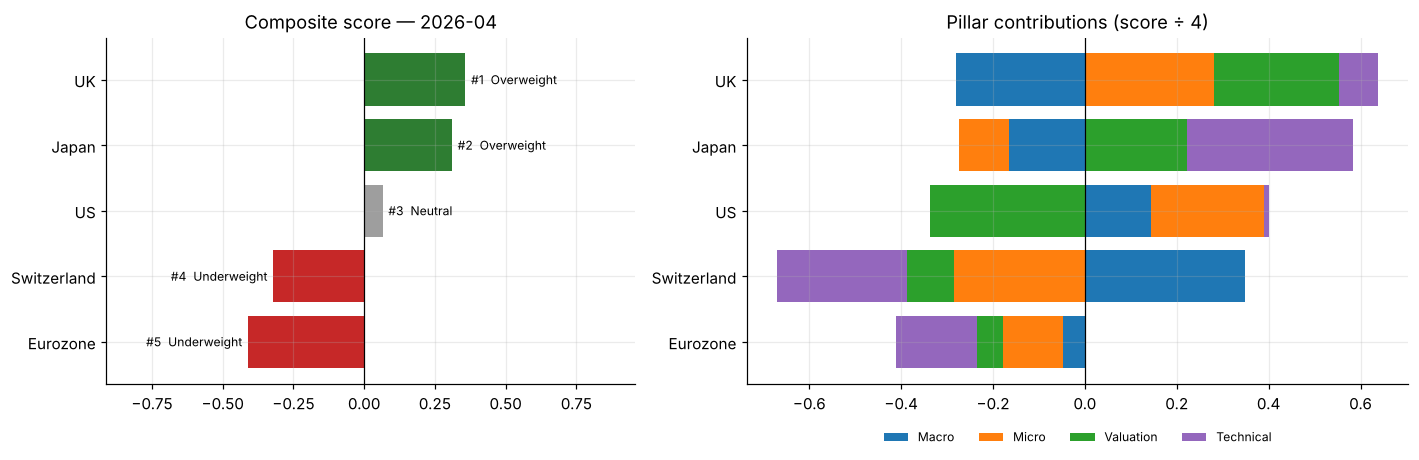

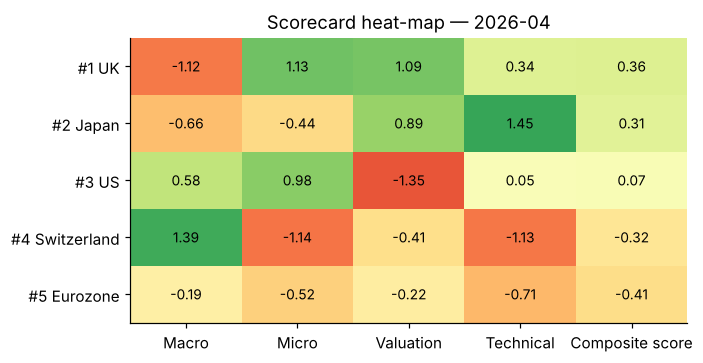

,PMI 3M chg (pts),EPS 3M revision,Fwd P/E,Fwd P/E z (own history),12-1M momentum
UK,+0.4,+10.2%,12.9,+0.38,+20.1%
Japan,+1.6,+4.8%,17.6,+0.46,+30.9%
US,+4.8,+9.7%,20.7,+1.37,+17.3%
Switzerland,+6.9,+2.4%,18.3,+0.99,+5.9%
Eurozone,+2.8,+4.6%,14.9,+0.91,+10.0%


In [15]:
cols = ['Macro', 'Micro', 'Valuation', 'Technical']
cc = [PCOLS[k] for k in PILLARS]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={'width_ratios': [1, 1.25]})
c2 = cur.sort_values('Composite score')
ax[0].barh(c2.index, c2['Composite score'], color=['#2e7d32' if s == 'Overweight' else '#c62828' if s == 'Underweight' else '#9e9e9e' for s in c2.Stance])
for i, (idx, rw) in enumerate(c2.iterrows()):
    ax[0].text(rw['Composite score'] + (0.02 if rw['Composite score'] >= 0 else -0.02), i, f"#{rw['Rank']}  {rw['Stance']}", va='center',
               ha='left' if rw['Composite score'] >= 0 else 'right', fontsize=8)
ax[0].axvline(0, color='k', lw=.8); ax[0].set_title(f'Composite score — {AS_OF}'); ax[0].set_xlim(c2['Composite score'].min() - .5, c2['Composite score'].max() + .6)
contrib = cur[cols] / 4
contrib = contrib.loc[c2.index]
pos = np.zeros(len(contrib)); neg = np.zeros(len(contrib))
for col, colr in zip(cols, cc):
    v = contrib[col].values; b = np.where(v >= 0, pos, neg)
    ax[1].barh(contrib.index, v, left=b, color=colr, label=col); pos = pos + np.where(v >= 0, v, 0); neg = neg + np.where(v < 0, v, 0)
ax[1].axvline(0, color='k', lw=.8); ax[1].set_title('Pillar contributions (score ÷ 4)'); ax[1].legend(fontsize=8, ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.1), frameon=False)
plt.tight_layout(); plt.savefig(CH/'fig_current_ranking.png', dpi=200, bbox_inches='tight'); plt.show()

# heat-map of current pillar z-scores
fig, a = plt.subplots(figsize=(6.5, 3.4))
hm = cur[cols + ['Composite score']]
im = a.imshow(hm.values, cmap='RdYlGn', vmin=-2, vmax=2, aspect='auto')
a.set_xticks(range(hm.shape[1])); a.set_xticklabels(hm.columns); a.set_yticks(range(len(hm))); a.set_yticklabels([f'#{r} {i}' for i, r in zip(hm.index, cur.Rank)])
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]): a.text(j, i, f'{hm.values[i, j]:.2f}', ha='center', va='center', fontsize=9)
a.grid(False); a.set_title(f'Scorecard heat-map — {AS_OF}'); plt.tight_layout(); plt.savefig(CH/'fig_scorecard_heatmap.png', dpi=200, bbox_inches='tight'); plt.show()

raw_now = pd.DataFrame({'PMI 3M chg (pts)': RAW_SIG['macro'].loc[AS_OF], 'EPS 3M revision': RAW_SIG['micro'].loc[AS_OF],
                        'Fwd P/E': PE.loc[AS_OF], 'Fwd P/E z (own history)': -RAW_SIG['val'].loc[AS_OF], '12-1M momentum': RAW_SIG['tech'].loc[AS_OF]}).loc[cur.index]
display(raw_now.style.format({'PMI 3M chg (pts)': '{:+.1f}', 'EPS 3M revision': '{:+.1%}', 'Fwd P/E': '{:.1f}', 'Fwd P/E z (own history)': '{:+.2f}', '12-1M momentum': '{:+.1%}'}))

## 8. Results summary & honest read-out

**How to read the result (static commentary written after inspecting the tables above):**
* The **pre-specified equal-weight composite shows no statistically reliable predictive power** and no robust backtest edge; it should **not** be presented as a proven alpha model.
* **EPS revision (micro)** is the only pillar with supporting evidence (positive IC at 3M and 6M, local and USD; permutation p-values 0.02–0.09).
* **PMI change (macro)** has a *negative* in-sample IC. It was **not** flipped: sign was fixed ex ante and flipping it now would be fitting to this sample. Possible structural reasons (PMI already priced in, cyclical-sector mix differences across markets) are hypotheses, not findings.
* **Valuation** and **momentum** are weak/unstable across the two half-samples.
* **Limitations:** only 5 markets (cross-sectional power is low); price is a *proxy* (P/E × EPS, price-return, no dividends); 186 months of history; gross of costs; US data ends Apr-2026 so the as-of date is Apr-2026 for all markets (others run to Jun/Jul-2026).
* **Research ledger:** Experiment 1 (this notebook) = equal-weight 4-pillar scorecard, 1 specification, no parameter search. Any later re-specification on this same history must be logged as a new experiment (selection risk rises with each).

*Auto-generated numbers:* (auto-generated from the numbers above)

In [16]:
g = lambda s, b, h, col: STATS[(STATS.Strategy == s) & (STATS.Basis == b) & (STATS['H (M)'] == h)][col].iloc[0]
ls_u, ls_l = 'A. Score-weighted L/S', 'A. Score-weighted L/S'
sig_tab = PP[(PP['Horizon (M)'] == 3) & (PP.Basis == 'USD')].set_index('Signal')
top, bot = cur.index[:2].tolist(), cur.index[-2:].tolist()
md = f"""
**Current view ({AS_OF}):** Overweight **{', '.join(top)}** · Neutral **{cur.index[2]}** · Underweight **{', '.join(bot)}**.

**Predictive power (USD, 3M):** composite IC = {sig_tab.loc['COMPOSITE (equal-weight)', 'Mean IC']:.3f}
(NW t = {sig_tab.loc['COMPOSITE (equal-weight)', 'IC t-stat (NW)']:.2f}, perm p = {sig_tab.loc['COMPOSITE (equal-weight)', 'Perm p-value (1-sided)']:.3f}); single-signal ICs range
{sig_tab['Mean IC'].drop('COMPOSITE (equal-weight)').min():.3f} to {sig_tab['Mean IC'].drop('COMPOSITE (equal-weight)').max():.3f}.

**Backtest ({bt_start} → {bt_end}, gross, H=3):** L/S USD Sharpe {g(ls_u,'USD',3,'Sharpe'):.2f}, ann. return {g(ls_u,'USD',3,'Ann. return'):.1%}, max DD {g(ls_u,'USD',3,'Max drawdown'):.1%};
local Sharpe {g(ls_l,'local',3,'Sharpe'):.2f}. Long-only top-2 vs EW benchmark (USD): active return {g('B. Top-2 minus EW benchmark (active)','USD',3,'Ann. return'):.1%} p.a., IR {g('B. Top-2 minus EW benchmark (active)','USD',3,'Info ratio'):.2f}.
"""
display(Markdown(md))


**Current view (2026-04):** Overweight **UK, Japan** · Neutral **US** · Underweight **Switzerland, Eurozone**.

**Predictive power (USD, 3M):** composite IC = 0.013
(NW t = 0.24, perm p = 0.400); single-signal ICs range
-0.049 to 0.080.

**Backtest (2010-12 → 2026-04, gross, H=3):** L/S USD Sharpe 0.05, ann. return 0.1%, max DD -26.9%;
local Sharpe 0.21. Long-only top-2 vs EW benchmark (USD): active return -0.8% p.a., IR -0.19.


## 9. Export CSVs (inputs & outputs)

In [17]:
# INPUT: cleaned monthly panel actually used by the model
inp = []
for c in COUNTRIES:
    d = pd.DataFrame({'date': PE.index.to_timestamp('M'), 'country': c, 'fwd_pe': PE[c].values, 'fwd_eps': EPS[c].values,
                      'pmi': PMI[c].values, 'fx_usd_per_local': FX[c].values, 'implied_price_local': PX[c].values,
                      'implied_price_usd': PX_USD[c].values}).dropna(subset=['fwd_pe', 'fwd_eps'])
    inp.append(d)
pd.concat(inp).to_csv(DATA/'scorecard_input_monthly.csv', index=False)

# OUTPUT 1: monthly signals, pillar scores, composite, rank
o = []
for c in COUNTRIES:
    d = pd.DataFrame({'date': SIG_IDX.to_timestamp('M'), 'country': c})
    for k in PILLARS:
        d[f'raw_{k}'] = RAW_SIG[k].loc[SIG_IDX, c].values
    for k in PILLARS:
        d[f'z_{k}'] = Z[k][c].values
    d['composite_score'] = COMP[c].values; d['rank'] = RANK.loc[SIG_IDX, c].astype(int).values
    d['stance'] = d['rank'].map(STANCE)
    for (basis, h), f in fwd.items():
        d[f'fwd_{h}m_ret_{basis}'] = f.loc[SIG_IDX, c].values
    o.append(d)
pd.concat(o).to_csv(OUT/'scorecard_monthly_scores.csv', index=False)

cur.reset_index(names='country').to_csv(OUT/'current_ranking.csv', index=False)
PP.to_csv(OUT/'predictive_power.csv', index=False)
STATS.to_csv(OUT/'backtest_stats.csv', index=False)
bt_out = pd.concat({f'{b}_H{h}': v for (b, h), v in BT.items()}, axis=1)
bt_out.index = bt_out.index.to_timestamp('M'); bt_out.to_csv(OUT/'backtest_monthly_returns.csv')
print('Saved:', *[p.name for p in sorted(list(DATA.glob('*.csv')) + list(OUT.glob('*.csv')))], sep='\n  ')

Saved:
  scorecard_input_monthly.csv
  backtest_monthly_returns.csv
  backtest_stats.csv
  current_ranking.csv
  predictive_power.csv
  scorecard_monthly_scores.csv
